<table style="width: 100%; border: none; background: #f8f9fa; padding: 20px; border-radius: 10px;">
    <tr>
        <td style="width: 22%; border: none; vertical-align: middle; text-align: center;">
            <img src="https://www.inf.ucv.cl/wp-content/uploads/2020/05/logo_escuela.jpg" width="170">
        </td>
        <td style="width: 56%; border: none; vertical-align: middle; text-align: center; padding: 0 20px;">
            <h1 style="font-size: 28px; color: #1a3b5c; margin-bottom: 16px; border-bottom: 2px solid #1a3b5c; padding-bottom: 8px;">Tarea 2: Clasificacion, Costos Asimetricos y Arboles</h1>
            <p style="font-size: 16px; margin: 8px 0;"><strong>Pontificia Universidad Catolica de Valparaiso</strong><br>
            <strong>Escuela de Ingenieria Informatica</strong></p>
            <p style="font-size: 14px; color: #333; margin: 12px 0;"><strong>OII432 Machine Learning</strong><br>
            <strong>Semestre: 2-2026</strong><br>
            <strong>Profesor: Carlos Valle</strong></p>
        </td>
        <td style="width: 22%; border: none; vertical-align: middle; text-align: center;">
            <img src="https://upload.wikimedia.org/wikipedia/commons/c/cb/PUCV_Escudo2016.svg" width="110">
        </td>
    </tr>
</table>

# Pregunta 2 - Desafio Kaggle
Integrantes:
- Nelson Fuentes
- Eduardo Pérez
- Eduardo Sandoval
- Ricardo Pastén

# Importación de librerías

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.model_selection import ParameterGrid
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    classification_report
)

plt.rcParams['figure.figsize'] = (12, 5)
sns.set_palette("deep")
np.random.seed(42)

# Explicación de los datos

### Carga de data

In [32]:
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')
sample_submission_df = pd.read_csv('sample_submission.csv')

### Inspección básica de data

In [33]:
train_df.head(3)

,id,pub_fecha,pub_titulo,pub_descripcion,pub_monto_estimado,pub_moneda,pub_metodo,pub_modalidad,pub_n_items,pub_cantidad_total,...,pub_cierre,pub_dias_postulacion,pub_tiene_consultas,pub_dias_consultas,comprador,comprador_id,comprador_rut,region,direccion,y_desierta
0,248328745624,2024-03-25T15:32:20Z,LP04-2024 AV. UNO SUR AYSEN,"CONSTRUCCIÓN CALZADA H.C.V. AVENIDA UNO SUR, P...",NaN,NaN,open,Licitación Pública MOP (O1),1,1.0,...,2024-04-12T10:00:00Z,17.769,False,11.0,SERVICIO DE VIVIENDA Y URBANIZACION XI REGION ...,CL-MP-1653,618230007,Región Aysén del General Carlos Ibáñez del Campo,RAMON FREIRE Nº 5,0
1,760555527084,2024-03-21T14:29:28Z,LICITACION PUBLICA PARA OBRAS DE INFRAESTRUCTU...,licitar las obras de infraestructura de mejora...,NaN,NaN,open,Licitación Pública entre a 2000 y 5000 UTM (LQ),1,1.0,...,2024-04-15T20:00:00Z,25.230,False,21.0,CORPORACION MUNICIPAL DE EDUCACION Y SALUD DE ...,CL-MP-1274286,709255002,Región Metropolitana de Santiago,O'HIGGINS 840,1
2,224829110991,2024-01-26T12:37:41Z,ADQUISICION DE INSUMOS DE ENFERMERÍA PARA DSM,ADQUISICION DE INSUMOS DE ENFERMERÍA PARA USUA...,3500000.0,CLP,open,Licitación Pública Menor a 100 UTM (L1),55,12150.0,...,2024-02-01T13:24:00Z,6.032,False,3.0,I MUNICIPALIDAD DE CHANCO | I MUNICIPALIDAD DE...,CL-MP-4391,69120300K,Región del Maule,Ignacio Carrera Pinto Nº 31,0


In [34]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152553 entries, 0 to 152552
Data columns (total 24 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    152553 non-null  int64  
 1   pub_fecha             152553 non-null  object 
 2   pub_titulo            152544 non-null  object 
 3   pub_descripcion       152544 non-null  object 
 4   pub_monto_estimado    85287 non-null   float64
 5   pub_moneda            85251 non-null   object 
 6   pub_metodo            152485 non-null  object 
 7   pub_modalidad         152553 non-null  object 
 8   pub_n_items           152553 non-null  int64  
 9   pub_cantidad_total    152553 non-null  float64
 10  pub_categoria         152528 non-null  object 
 11  pub_categoria_id      152528 non-null  float64
 12  pub_n_categorias      152553 non-null  int64  
 13  pub_inicio            152553 non-null  object 
 14  pub_cierre            152526 non-null  object 
 15  

In [35]:
test_df.head(3)

,id,pub_fecha,pub_titulo,pub_descripcion,pub_monto_estimado,pub_moneda,pub_metodo,pub_modalidad,pub_n_items,pub_cantidad_total,...,pub_inicio,pub_cierre,pub_dias_postulacion,pub_tiene_consultas,pub_dias_consultas,comprador,comprador_id,comprador_rut,region,direccion
0,47254358932,2025-03-12T15:46:53Z,SC 36914 (CM) ADQUISICIÓN DE MOBILIARIO PARA C...,ADQUISICIÓN DE MOBILIARIO PARA CLÍNICA JURÍDIC...,4999999.0,CLP,open,Licitación Pública Menor a 100 UTM (L1),3,24.0,...,2025-03-12T15:46:47Z,2025-03-20T15:30:00Z,7.988,False,2.0,UNIVERSIDAD DE PLAYA ANCHA DE CIENCIAS DE LA E...,CL-MP-5385,707547006,Región Metropolitana de Santiago,Av. A Bello 2687
1,295671198916,2025-01-06T17:34:25Z,COMPRA DE MEDICAMENTOS PARA DEPTO SALUD MAULE,COMPRA DE MEDICAMENTOS PARA DEPTO SALUD MAULE,20000000.0,CLP,open,Licitación Pública Entre 100 y 1000 UTM (LE),45,123593.0,...,2025-01-06T17:34:19Z,2025-01-16T19:53:00Z,10.096,False,3.0,I MUNICIPALIDAD DE MAULE | I MUNICIPALIDAD DE ...,CL-MP-5605,691109003,Región del Maule,Balmaceda N° 350
2,214756376398,2025-02-26T12:48:51Z,ADQUISICIÓN DE BOLSAS CORPORATIVAS REUTILIZABL...,ADQUISICIÓN DE BOLSAS CORPORATIVAS REUTILIZABL...,NaN,NaN,open,Licitación Pública Entre 100 y 1000 UTM (LE),1,19000.0,...,2025-02-26T12:48:41Z,2025-03-03T15:00:00Z,5.091,False,2.0,I MUNICIPALIDAD DE QUILICURA | DEPARTAMENTO CO...,CL-MP-3475,690713004,Región Metropolitana de Santiago,NaN


In [36]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21829 entries, 0 to 21828
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    21829 non-null  int64  
 1   pub_fecha             21829 non-null  object 
 2   pub_titulo            21829 non-null  object 
 3   pub_descripcion       21829 non-null  object 
 4   pub_monto_estimado    10230 non-null  float64
 5   pub_moneda            10226 non-null  object 
 6   pub_metodo            21734 non-null  object 
 7   pub_modalidad         21829 non-null  object 
 8   pub_n_items           21829 non-null  int64  
 9   pub_cantidad_total    21829 non-null  float64
 10  pub_categoria         21828 non-null  object 
 11  pub_categoria_id      21828 non-null  float64
 12  pub_n_categorias      21829 non-null  int64  
 13  pub_inicio            21829 non-null  object 
 14  pub_cierre            21823 non-null  object 
 15  pub_dias_postulacio

In [37]:
sample_submission_df.head(3)

,id,y_desierta
0,47254358932,1
1,295671198916,1
2,214756376398,1


In [38]:
sample_submission_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21829 entries, 0 to 21828
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          21829 non-null  int64
 1   y_desierta  21829 non-null  int64
dtypes: int64(2)
memory usage: 341.2 KB


In [39]:
assert list(sample_submission_df.columns) == ["id", "y_desierta"]
assert sample_submission_df["id"].equals(test_df["id"])
print("sample_submission se usa solo como plantilla de formato; su columna y_desierta no se usa como etiqueta ni prevalencia.")

sample_submission se usa solo como plantilla de formato; su columna y_desierta no se usa como etiqueta ni prevalencia.


### ¿El conjunto de entrenamiento está desbalanceado?

In [40]:
train_df.value_counts('y_desierta')

y_desierta
0    122006
1     30547
Name: count, dtype: int64

In [41]:
train_df["y_desierta"].value_counts(normalize=True) * 100

y_desierta
0    79.976139
1    20.023861
Name: proportion, dtype: float64

### El conjunto de entrenamiento está desbalanceado.
Se tiene un desbalance respecto de la variable objetivo. Debido a que se tiene una proporción de 4:1. Dónde por **cada licitación desierta** (clase 1) hay **4 licitaciones no desiertas** (clase 0).

### ¿Cuántos valores nulos hay?

In [42]:
train_df.isnull().sum()

id                          0
pub_fecha                   0
pub_titulo                  9
pub_descripcion             9
pub_monto_estimado      67266
pub_moneda              67302
pub_metodo                 68
pub_modalidad               0
pub_n_items                 0
pub_cantidad_total          0
pub_categoria              25
pub_categoria_id           25
pub_n_categorias            0
pub_inicio                  0
pub_cierre                 27
pub_dias_postulacion       23
pub_tiene_consultas         0
pub_dias_consultas         68
comprador                   0
comprador_id                0
comprador_rut              35
region                     10
direccion                8196
y_desierta                  0
dtype: int64

In [43]:
100 * 67266 / 152553 

44.09352815087215

pub_monto_estimado y pub_moneda tienen alrededor del 44% de valores nulos respecto del total de registros.

### ¿Existirá una relación entre los montos nulos respecto de las monedas?

In [44]:
pd.crosstab(
    train_df["pub_monto_estimado"].isna(),
    train_df["pub_moneda"].isna(),
    rownames=["Monto nulo"],
    colnames=["Moneda nula"]
)

Moneda nula,False,True
Monto nulo,,
False,85251,36
True,0,67266


Hay 67.266 registros con montos nulos y monedas nulas.

In [45]:
resumen = train_df.groupby(
    "pub_moneda", dropna=False
)["pub_monto_estimado"].agg(
    total="size",
    nulos=lambda x: x.isna().sum(),
    porcentaje_nulos=lambda x: x.isna().mean() * 100
)

resumen.sort_values("porcentaje_nulos", ascending=False)

,total,nulos,porcentaje_nulos
pub_moneda,,,
NaN,67302,67266,99.94651
CLF,623,0,0.00000
CLP,84116,0,0.00000
EUR,2,0,0.00000
USD,510,0,0.00000


Todos los registros con montos nulos tienen monedas nulas. Mientras que, hay monedas nulas que pertenecen a registros con montos no nulos.

### ¿Existirá una relación entre los montos nulos respecto de las categorías?

In [46]:
resumen_categoria_montos = train_df.groupby("pub_categoria")["pub_monto_estimado"].agg(
    total="size",
    nulos=lambda x: x.isna().sum(),
    porcentaje_nulos=lambda x: x.isna().mean() * 100
)

resumen_categoria_montos[
    (resumen_categoria_montos["porcentaje_nulos"] == 100) &
    (resumen_categoria_montos["total"] >= 30)
].sort_values("total", ascending=False)

,total,nulos,porcentaje_nulos
pub_categoria,,,
Obras MINVU / Obras MINVU / Grupo 2 / 3°,190,190,100.0
Obras MINVU / Obras MINVU / Grupo 2 / 2°,105,105,100.0
Obras MINVU / Obras MINVU / Grupo 2 / 1°,85,85,100.0
Obras / Obras Mayores / Obra Civil / 2da,77,77,100.0
Consultoria / Consultoria / Inspecciones / 1a S,71,71,100.0
Obras /Obras Menores/Obra Menor / A,48,48,100.0
Consultoria / Consultoria / Ingeniería Civil / 1a S,47,47,100.0
Consultoria / Consultoria / Inspecciones / 2da,41,41,100.0
Obras / Obras Mayores / Obra Civil / 3,39,39,100.0


Existen categorias con todos sus montos nulos, pero la conclusion depende del numero de registros. Por eso se revisan primero las categorias con al menos 30 observaciones; las categorias con muy pocos casos se tratan como evidencia debil y no como un patron estable.

### Tratamiento metodologico de montos y objetivo

Para evitar seleccion de variables influida por el periodo de evaluacion final, no se usa una relacion exploratoria calculada con todo 2024 entre montos/categorias y `y_desierta` antes de definir las particiones temporales. Los montos se tratan de forma no supervisada: se conservan indicadores de ausencia y la moneda como categoria, pero se omite el valor bruto porque mezcla unidades monetarias sin conversion temporal verificable.

In [47]:
resumen_monto_no_supervisado = pd.DataFrame({
    "registros": [len(train_df)],
    "monto_nulo_pct": [train_df["pub_monto_estimado"].isna().mean() * 100],
    "moneda_nula_pct": [train_df["pub_moneda"].isna().mean() * 100],
    "monedas_distintas": [train_df["pub_moneda"].nunique(dropna=True)]
})
resumen_monto_no_supervisado

,registros,monto_nulo_pct,moneda_nula_pct,monedas_distintas
0,152553,44.093528,44.117127,4


In [48]:
resumen_categoria_montos[
    resumen_categoria_montos["total"] >= 30
].sort_values(["porcentaje_nulos", "total"], ascending=[False, False]).head(20)

,total,nulos,porcentaje_nulos
pub_categoria,,,
Obras MINVU / Obras MINVU / Grupo 2 / 3°,190,190,100.000000
Obras MINVU / Obras MINVU / Grupo 2 / 2°,105,105,100.000000
Obras MINVU / Obras MINVU / Grupo 2 / 1°,85,85,100.000000
Obras / Obras Mayores / Obra Civil / 2da,77,77,100.000000
Consultoria / Consultoria / Inspecciones / 1a S,71,71,100.000000
Obras /Obras Menores/Obra Menor / A,48,48,100.000000
Consultoria / Consultoria / Ingeniería Civil / 1a S,47,47,100.000000
Consultoria / Consultoria / Inspecciones / 2da,41,41,100.000000
Obras / Obras Mayores / Obra Civil / 3,39,39,100.000000


### Separación de variables

In [49]:
X = train_df.drop(columns=["y_desierta"])
y = train_df["y_desierta"]

print("X:", X.shape)
print("y:", y.shape)

X: (152553, 23)
y: (152553,)


### Verificación de fechas inválidas

In [50]:
datos = train_df.copy()

datos["pub_fecha"] = pd.to_datetime(
    datos["pub_fecha"],
    errors="coerce",
    utc=True
)

print("Fechas invalidas:", datos["pub_fecha"].isna().sum())

Fechas invalidas: 0


Al no haber fechas invalidas, podemos crear variables a partir de la fecha de publicacion. Para la validacion se usan cortes temporales sucesivos: un periodo para ajustar hiperparametros, otro para seleccionar el umbral y un ultimo tramo para estimar el desempeno final sin reutilizar los mismos datos.

In [51]:
CORTE_HPARAM = pd.Timestamp("2024-08-01", tz="UTC")
CORTE_UMBRAL = pd.Timestamp("2024-10-01", tz="UTC")
CORTE_EVALUACION = pd.Timestamp("2024-11-15", tz="UTC")

train_modelos = datos[datos["pub_fecha"] < CORTE_HPARAM].copy()
val_hparam = datos[
    (datos["pub_fecha"] >= CORTE_HPARAM) &
    (datos["pub_fecha"] < CORTE_UMBRAL)
].copy()
val_umbral = datos[
    (datos["pub_fecha"] >= CORTE_UMBRAL) &
    (datos["pub_fecha"] < CORTE_EVALUACION)
].copy()
test_temporal = datos[datos["pub_fecha"] >= CORTE_EVALUACION].copy()

train_hparam = pd.concat([train_modelos, val_hparam], axis=0)
train_umbral = pd.concat([train_hparam, val_umbral], axis=0)

print("Entrenamiento modelos:", train_modelos.shape)
print("Validacion hiperparametros:", val_hparam.shape)
print("Validacion umbral:", val_umbral.shape)
print("Evaluacion temporal final:", test_temporal.shape)

Entrenamiento modelos: (90904, 24)
Validacion hiperparametros: (25762, 24)
Validacion umbral: (21308, 24)
Evaluacion temporal final: (14579, 24)


# Construccion de features

La senal se organiza en tres grupos compatibles con el marco anti-leakage:

- **Texto publicado:** titulo y descripcion concatenados, vectorizados con TF-IDF dentro del pipeline. Se usa como hipotesis de trabajo que estos campos corresponden a la version disponible al publicar; sin diccionario oficial no se puede certificar si hubo ediciones posteriores.
- **Plazos y estructura:** cantidades, numero de items, dias de postulacion/consultas, fecha, flags de faltantes y moneda. El valor monetario bruto se excluye porque mezcla monedas sin conversion temporal verificable.
- **Conteos historicos seguros:** numero de publicaciones anteriores por comprador, categoria y combinacion comprador-categoria. No usan `y_desierta` ni tasas de desenlace.

Por regla del archivo `MARCO_TRABAJO_ANTI_DATA_LEAKAGE.md`, se eliminan las tasas historicas de licitaciones desiertas, suavizados con prevalencia global y cualquier target encoding. Como no hay fecha de disponibilidad del desenlace, ninguna caracteristica historica puede depender de etiquetas. La validacion se describe como validacion retrospectiva por fecha de publicacion, no como simulacion operacional perfecta de disponibilidad de resultados.

### Preparación de características sin fuga temporal

In [52]:
BASE_NUMERICAS = [
    "pub_n_items",
    "pub_cantidad_total",
    "pub_n_categorias",
    "pub_dias_postulacion",
    "pub_dias_consultas",
    "monto_nulo",
    "moneda_nula",
    "titulo_largo",
    "descripcion_larga",
    "texto_palabras",
    "mes_publicacion",
    "dia_semana_publicacion",
    "cat_niveles"
]

HISTORICAS = [
    "hist_comprador_n",
    "hist_categoria_n",
    "hist_comprador_categoria_n",
    "comprador_nuevo",
    "categoria_nueva"
]

NUMERICAS = BASE_NUMERICAS + HISTORICAS

CATEGORICAS = [
    "pub_metodo",
    "pub_modalidad",
    "pub_moneda",
    "region",
    "categoria_principal"
]

TARGET = "y_desierta"

def normalizar_llave(serie):
    return serie.fillna("desconocido").astype(str)

def crear_features_base(df):
    X = df.copy()

    X["pub_fecha"] = pd.to_datetime(X["pub_fecha"], errors="coerce", utc=True)
    X["texto"] = (
        X["pub_titulo"].fillna("").astype(str) + " " +
        X["pub_descripcion"].fillna("").astype(str)
    )

    X["titulo_largo"] = X["pub_titulo"].fillna("").astype(str).str.len()
    X["descripcion_larga"] = X["pub_descripcion"].fillna("").astype(str).str.len()
    X["texto_palabras"] = X["texto"].str.split().str.len()

    X["pub_monto_estimado"] = pd.to_numeric(X["pub_monto_estimado"], errors="coerce")
    X["monto_nulo"] = X["pub_monto_estimado"].isna().astype(int)
    X["moneda_nula"] = X["pub_moneda"].isna().astype(int)

    X["mes_publicacion"] = X["pub_fecha"].dt.month
    X["dia_semana_publicacion"] = X["pub_fecha"].dt.dayofweek

    categoria = X["pub_categoria"].fillna("desconocido").astype(str)
    X["categoria_principal"] = categoria.str.split("/").str[0].str.strip()
    X["cat_niveles"] = categoria.str.count("/") + 1

    for col in ["pub_n_items", "pub_cantidad_total", "pub_n_categorias",
                "pub_dias_postulacion", "pub_dias_consultas"]:
        X[col] = pd.to_numeric(X[col], errors="coerce")

    for col in CATEGORICAS:
        X[col] = X[col].fillna("desconocido").astype(str)

    X["comprador_key"] = normalizar_llave(X["comprador_id"])
    X["categoria_key"] = normalizar_llave(X["pub_categoria_id"])
    X["comprador_categoria_key"] = X["comprador_key"] + "|" + X["categoria_key"]
    return X

def llave_compuesta(df, keys):
    if len(keys) == 1:
        return df[keys[0]].astype(str).tolist()
    return list(map(tuple, df[keys].astype(str).to_numpy()))

def agregar_conteo_historico(df, referencia, keys, prefijo):
    ref = referencia[keys + ["pub_fecha"]].dropna(subset=["pub_fecha"]).copy()
    ref["__key"] = llave_compuesta(ref, keys)
    ref["__fecha_ns"] = ref["pub_fecha"].astype("int64")

    fechas_por_key = {
        key: np.sort(grupo["__fecha_ns"].to_numpy())
        for key, grupo in ref.groupby("__key", sort=False)
    }

    row_keys = llave_compuesta(df, keys)
    row_fechas = df["pub_fecha"].astype("int64").to_numpy()
    previos = np.array([
        np.searchsorted(fechas_por_key.get(key, np.array([], dtype=np.int64)), fecha, side="left")
        for key, fecha in zip(row_keys, row_fechas)
    ])

    return pd.DataFrame(
        {f"hist_{prefijo}_n": np.log1p(previos)},
        index=df.index
    )

def construir_features(df, referencia=None):
    X = crear_features_base(df)
    ref = X if referencia is None else crear_features_base(referencia)

    X[["hist_comprador_n"]] = agregar_conteo_historico(
        X, ref, ["comprador_key"], "comprador"
    )
    X[["hist_categoria_n"]] = agregar_conteo_historico(
        X, ref, ["categoria_key"], "categoria"
    )
    X[["hist_comprador_categoria_n"]] = agregar_conteo_historico(
        X, ref, ["comprador_categoria_key"], "comprador_categoria"
    )

    X["comprador_nuevo"] = (X["hist_comprador_n"] == 0).astype(int)
    X["categoria_nueva"] = (X["hist_categoria_n"] == 0).astype(int)

    columnas_modelo = NUMERICAS + CATEGORICAS + ["texto"]
    return X[columnas_modelo]

X_train_modelos = construir_features(train_modelos)
X_val_hparam = construir_features(val_hparam, referencia=train_modelos)
X_train_hparam = construir_features(train_hparam)
X_val_umbral = construir_features(val_umbral, referencia=train_hparam)
X_train_umbral = construir_features(train_umbral)
X_test_temporal = construir_features(test_temporal, referencia=train_umbral)

y_train_modelos = train_modelos[TARGET].astype(int)
y_val_hparam = val_hparam[TARGET].astype(int)
y_train_hparam = train_hparam[TARGET].astype(int)
y_val_umbral = val_umbral[TARGET].astype(int)
y_train_umbral = train_umbral[TARGET].astype(int)
y_test_temporal = test_temporal[TARGET].astype(int)

print("Features entrenamiento modelos:", X_train_modelos.shape)
print("Features validacion hiperparametros:", X_val_hparam.shape)
print("Features validacion umbral:", X_val_umbral.shape)
print("Features evaluacion temporal:", X_test_temporal.shape)
X_train_modelos.head()

Features entrenamiento modelos: (90904, 24)
Features validacion hiperparametros: (25762, 24)
Features validacion umbral: (21308, 24)
Features evaluacion temporal: (14579, 24)


,pub_n_items,pub_cantidad_total,pub_n_categorias,pub_dias_postulacion,pub_dias_consultas,monto_nulo,moneda_nula,titulo_largo,descripcion_larga,texto_palabras,...,hist_categoria_n,hist_comprador_categoria_n,comprador_nuevo,categoria_nueva,pub_metodo,pub_modalidad,pub_moneda,region,categoria_principal,texto
0,1,1.0,1,17.769,11.0,1,1,27,57,13,...,2.564949,0.000000,0,0,open,Licitación Pública MOP (O1),desconocido,Región Aysén del General Carlos Ibáñez del Campo,Obras MINVU,LP04-2024 AV. UNO SUR AYSEN CONSTRUCCIÓN CALZA...
1,1,1.0,1,25.230,21.0,1,1,61,146,32,...,7.433667,1.386294,0,0,open,Licitación Pública entre a 2000 y 5000 UTM (LQ),desconocido,Región Metropolitana de Santiago,Servicios de construcción y mantenimiento,LICITACION PUBLICA PARA OBRAS DE INFRAESTRUCTU...
2,55,12150.0,27,6.032,3.0,0,0,45,115,25,...,0.000000,0.000000,0,1,open,Licitación Pública Menor a 100 UTM (L1),CLP,Región del Maule,Equipamiento para laboratorios,ADQUISICION DE INSUMOS DE ENFERMERÍA PARA DSM ...
3,1,350.0,1,6.234,1.0,0,0,15,69,14,...,3.737670,2.079442,0,0,open,Licitación Pública Menor a 100 UTM (L1),CLP,Región Metropolitana de Santiago,Equipamiento y suministros médicos,GASA HIDROFILA SC 309 - SP 742 IDDOC 718225...
6,1,1.0,1,7.150,3.0,1,1,39,63,14,...,3.135494,0.000000,0,0,open,Licitación Pública Menor a 100 UTM (L1),desconocido,Región Metropolitana de Santiago,Artículos para plantas y animales,Adquisición de Insecticidas y Raticidas Adquis...


In [53]:
def ejecutar_pruebas_aceptacion():
    assert TARGET in train_df.columns
    assert TARGET not in test_df.columns
    assert set(train_df[TARGET].dropna().unique()).issubset({0, 1})
    assert train_df["id"].is_unique
    assert test_df["id"].is_unique
    assert sample_submission_df["id"].equals(test_df["id"])
    assert len(train_df) == 152553
    assert len(test_df) == 21829

    bloques = {
        "A": train_modelos,
        "B": val_hparam,
        "C": val_umbral,
        "D": test_temporal
    }
    assert sum(len(bloque) for bloque in bloques.values()) == len(train_df)
    assert datos["pub_fecha"].notna().all()
    for nombre_1, bloque_1 in bloques.items():
        for nombre_2, bloque_2 in bloques.items():
            if nombre_1 < nombre_2:
                assert set(bloque_1["id"]).isdisjoint(set(bloque_2["id"]))

    columnas_modelo = NUMERICAS + CATEGORICAS + ["texto"]
    columnas_prohibidas = {"id", TARGET, "pub_monto_estimado"}
    assert columnas_prohibidas.isdisjoint(columnas_modelo)
    assert not any("tasa" in col.lower() for col in columnas_modelo)

    muestra = train_hparam.sort_values("pub_fecha").head(200).copy()
    features_base = construir_features(muestra)
    muestra_y_alterada = muestra.copy()
    muestra_y_alterada[TARGET] = np.random.default_rng(42).integers(0, 2, size=len(muestra_y_alterada))
    pd.testing.assert_frame_equal(features_base, construir_features(muestra_y_alterada))

    pasado = train_hparam.sort_values("pub_fecha").head(100).copy()
    futuro = test_temporal.sort_values("pub_fecha").tail(100).copy()
    features_pasado = construir_features(pasado).reset_index(drop=True)
    features_pasado_con_futuro = construir_features(
        pd.concat([pasado, futuro], axis=0, sort=False)
    ).iloc[:len(pasado)].reset_index(drop=True)
    pd.testing.assert_frame_equal(features_pasado, features_pasado_con_futuro)

    features_auditoria = construir_features(train_hparam)
    muestra_auditoria = train_hparam.sample(n=10, random_state=42)
    base_auditoria = crear_features_base(train_hparam)
    for idx, fila in muestra_auditoria.iterrows():
        fila_base = crear_features_base(pd.DataFrame([fila])).iloc[0]
        fecha = fila_base["pub_fecha"]
        comprador = fila_base["comprador_key"]
        categoria = fila_base["categoria_key"]
        comprador_categoria = fila_base["comprador_categoria_key"]

        assert np.isclose(
            features_auditoria.loc[idx, "hist_comprador_n"],
            np.log1p(((base_auditoria["comprador_key"] == comprador) & (base_auditoria["pub_fecha"] < fecha)).sum())
        )
        assert np.isclose(
            features_auditoria.loc[idx, "hist_categoria_n"],
            np.log1p(((base_auditoria["categoria_key"] == categoria) & (base_auditoria["pub_fecha"] < fecha)).sum())
        )
        assert np.isclose(
            features_auditoria.loc[idx, "hist_comprador_categoria_n"],
            np.log1p(((base_auditoria["comprador_categoria_key"] == comprador_categoria) & (base_auditoria["pub_fecha"] < fecha)).sum())
        )

    print("Pruebas de aceptacion anti-leakage superadas.")

ejecutar_pruebas_aceptacion()

Pruebas de aceptacion anti-leakage superadas.


### Pipelines de preprocesamiento

In [54]:
def crear_one_hot():
    try:
        return OneHotEncoder(handle_unknown="ignore", min_frequency=20)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore")

def crear_preprocesamiento(incluir_texto=True, incluir_historial=True):
    numericas = NUMERICAS if incluir_historial else BASE_NUMERICAS

    transformadores = [
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler(with_mean=False))
        ]), numericas),
        ("cat", crear_one_hot(), CATEGORICAS)
    ]

    if incluir_texto:
        transformadores.append(
            ("texto", TfidfVectorizer(
                max_features=20000,
                min_df=5,
                ngram_range=(1, 2),
                sublinear_tf=True
            ), "texto")
        )

    return ColumnTransformer(transformadores)

preprocesamiento_full = crear_preprocesamiento(incluir_texto=True, incluir_historial=True)
preprocesamiento_estructural = crear_preprocesamiento(incluir_texto=False, incluir_historial=False)
preprocesamiento_sin_historial = crear_preprocesamiento(incluir_texto=True, incluir_historial=False)

# Modelos explorados

Se comparan modelos estructurales y regresiones logisticas para distinguir el aporte de cada bloque de features:

- Un **arbol estructural** y un **bosque estructural** como baselines tabulares opcionales.
- Una **regresion logistica estructural**, sin texto ni conteos historicos.
- Una **regresion logistica con texto y sin conteos**, para aislar el aporte de TF-IDF.
- Una **regresion logistica con texto y conteos historicos seguros**, para medir el aporte adicional de historial no supervisado.

TF-IDF se usa porque los textos son dispersos y de longitud variable; One-Hot Encoding permite usar categorias nominales sin imponer orden; el escalamiento ayuda a que la regularizacion de la regresion logistica trate las variables numericas en escalas comparables; y la regularizacion limita pesos extremos en un espacio con muchas columnas. La imputacion se hace con mediana para variables numericas porque es mas robusta frente a colas largas y valores extremos que la media, y los flags de faltantes permiten que el modelo conserve informacion sobre ausencia de datos. Estos parametros son decisiones razonables de partida, no valores optimos salvo que la busqueda experimental los respalde.

La comparacion respeta el orden temporal: se entrenan modelos con datos anteriores al 2024-08-01, se optimizan hiperparametros entre 2024-08-01 y 2024-09-30, se selecciona el umbral entre 2024-10-01 y 2024-11-14 y se evalua finalmente desde 2024-11-15 en adelante. Este protocolo es una validacion retrospectiva por fecha de publicacion; no prueba disponibilidad operacional completa de etiquetas porque el CSV no contiene fechas de publicacion del desenlace.

In [55]:
def mejor_umbral_f1(y_true, proba):
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    idx = int(np.nanargmax(f1))
    return thresholds[idx], f1[idx], precision[idx], recall[idx]

def metricas_con_umbral(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        "threshold": threshold,
        "f1": f1_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "ap": average_precision_score(y_true, proba),
        "roc_auc": roc_auc_score(y_true, proba),
        "brier": brier_score_loss(y_true, proba),
        "tasa_observada": y_true.mean(),
        "tasa_predicha": pred.mean(),
        "matriz_confusion": confusion_matrix(y_true, pred)
    }

def evaluar_pipeline(nombre, pipeline, X_tr, y_tr, X_va, y_va, threshold=0.5):
    pipeline.fit(X_tr, y_tr)
    proba = pipeline.predict_proba(X_va)[:, 1]
    metricas = metricas_con_umbral(y_va, proba, threshold=threshold)
    metricas.update({"modelo": nombre, "pipeline": pipeline})
    return metricas

def clasificador_logistico(C=1.0, class_weight="balanced"):
    return LogisticRegression(
        C=C,
        class_weight=class_weight,
        solver="liblinear",
        max_iter=1000,
        random_state=42
    )

modelos_base = {
    "arbol_estructural": Pipeline([
        ("pre", preprocesamiento_estructural),
        ("clf", DecisionTreeClassifier(
            max_depth=10,
            min_samples_leaf=100,
            class_weight="balanced",
            random_state=42
        ))
    ]),
    "bosque_estructural": Pipeline([
        ("pre", preprocesamiento_estructural),
        ("clf", RandomForestClassifier(
            n_estimators=250,
            max_depth=14,
            min_samples_leaf=50,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=42
        ))
    ]),
    "logistica_estructural": Pipeline([
        ("pre", preprocesamiento_estructural),
        ("clf", clasificador_logistico())
    ]),
    "logistica_texto_sin_conteos": Pipeline([
        ("pre", preprocesamiento_sin_historial),
        ("clf", clasificador_logistico())
    ]),
    "logistica_texto_conteos": Pipeline([
        ("pre", preprocesamiento_full),
        ("clf", clasificador_logistico())
    ])
}

resultados_base = [
    evaluar_pipeline(nombre, clone(modelo), X_train_modelos, y_train_modelos, X_val_hparam, y_val_hparam)
    for nombre, modelo in modelos_base.items()
]

tabla_base = (
    pd.DataFrame(resultados_base)
    .drop(columns=["pipeline", "matriz_confusion"])
    .sort_values("ap", ascending=False)
)
tabla_base

,threshold,f1,precision,recall,ap,roc_auc,brier,tasa_observada,tasa_predicha,modelo
4,0.5,0.368198,0.295215,0.489118,0.326591,0.646435,0.211250,0.199752,0.330953,logistica_texto_conteos
3,0.5,0.370196,0.292375,0.504469,0.325496,0.645414,0.214360,0.199752,0.344655,logistica_texto_sin_conteos
1,0.5,0.366386,0.243826,0.736689,0.296322,0.623858,0.235871,0.199752,0.603525,bosque_estructural
2,0.5,0.352891,0.256431,0.565682,0.285126,0.611007,0.237120,0.199752,0.440649,logistica_estructural
0,0.5,0.361408,0.229850,0.845122,0.268504,0.598047,0.240602,0.199752,0.734454,arbol_estructural


# Busqueda de hiperparametros

La busqueda usa una validacion temporal dedicada a hiperparametros. No se usa validacion cruzada aleatoria porque mezclaria licitaciones posteriores dentro del ajuste de meses anteriores. La seleccion se ordena por Average Precision, una metrica independiente del umbral, y el umbral F1 se elige despues en otro periodo.

In [56]:
grillas = {
    "logistica_estructural": {
        "modelo": modelos_base["logistica_estructural"],
        "params": {
            "clf__C": [0.3, 1.0, 3.0],
            "clf__class_weight": [None, "balanced"]
        }
    },
    "logistica_texto_sin_conteos": {
        "modelo": modelos_base["logistica_texto_sin_conteos"],
        "params": {
            "clf__C": [0.3, 1.0, 3.0],
            "clf__class_weight": [None, "balanced"]
        }
    },
    "logistica_texto_conteos": {
        "modelo": modelos_base["logistica_texto_conteos"],
        "params": {
            "clf__C": [0.3, 1.0, 3.0],
            "clf__class_weight": [None, "balanced"]
        }
    },
    "arbol_estructural": {
        "modelo": modelos_base["arbol_estructural"],
        "params": {
            "clf__max_depth": [6, 10, 14, 18],
            "clf__min_samples_leaf": [50, 100, 200],
            "clf__class_weight": [None, "balanced"]
        }
    }
}

resultados_busqueda = []

for nombre, spec in grillas.items():
    for params in ParameterGrid(spec["params"]):
        candidato = clone(spec["modelo"]).set_params(**params)
        resultado = evaluar_pipeline(
            nombre,
            candidato,
            X_train_modelos,
            y_train_modelos,
            X_val_hparam,
            y_val_hparam
        )
        resultado["params"] = params
        resultados_busqueda.append(resultado)

tabla_busqueda = (
    pd.DataFrame(resultados_busqueda)
    .drop(columns=["pipeline", "matriz_confusion"])
    .sort_values("ap", ascending=False)
    .reset_index(drop=True)
)

tabla_busqueda.head(10)

,threshold,f1,precision,recall,ap,roc_auc,brier,tasa_observada,tasa_predicha,modelo,params
0,0.5,0.077713,0.683871,0.041197,0.337993,0.654777,0.150651,0.199752,0.012033,logistica_texto_conteos,"{'clf__C': 0.3, 'clf__class_weight': None}"
1,0.5,0.076979,0.677419,0.040808,0.336248,0.654147,0.150725,0.199752,0.012033,logistica_texto_sin_conteos,"{'clf__C': 0.3, 'clf__class_weight': None}"
2,0.5,0.378176,0.300804,0.509133,0.335352,0.654626,0.214378,0.199752,0.338095,logistica_texto_conteos,"{'clf__C': 0.3, 'clf__class_weight': 'balanced'}"
3,0.5,0.377219,0.293913,0.526428,0.333704,0.653645,0.217702,0.199752,0.357775,logistica_texto_sin_conteos,"{'clf__C': 0.3, 'clf__class_weight': 'balanced'}"
4,0.5,0.101221,0.566337,0.055577,0.332708,0.650083,0.151766,0.199752,0.019603,logistica_texto_conteos,"{'clf__C': 1.0, 'clf__class_weight': None}"
5,0.5,0.103460,0.565637,0.056937,0.331463,0.649271,0.151858,0.199752,0.020107,logistica_texto_sin_conteos,"{'clf__C': 1.0, 'clf__class_weight': None}"
6,0.5,0.368198,0.295215,0.489118,0.326591,0.646435,0.211250,0.199752,0.330953,logistica_texto_conteos,"{'clf__C': 1.0, 'clf__class_weight': 'balanced'}"
7,0.5,0.370196,0.292375,0.504469,0.325496,0.645414,0.214360,0.199752,0.344655,logistica_texto_sin_conteos,"{'clf__C': 1.0, 'clf__class_weight': 'balanced'}"
8,0.5,0.153369,0.478128,0.091333,0.320590,0.639424,0.155578,0.199752,0.038157,logistica_texto_conteos,"{'clf__C': 3.0, 'clf__class_weight': None}"
9,0.5,0.159275,0.476744,0.095608,0.319348,0.638388,0.155871,0.199752,0.040059,logistica_texto_sin_conteos,"{'clf__C': 3.0, 'clf__class_weight': None}"


In [57]:
mejor_idx = int(pd.DataFrame(resultados_busqueda)["ap"].idxmax())
mejor_resultado_hparam = resultados_busqueda[mejor_idx]
mejor_modelo_config = clone(grillas[mejor_resultado_hparam["modelo"]]["modelo"]).set_params(
    **mejor_resultado_hparam["params"]
)

modelo_para_umbral = clone(mejor_modelo_config)
modelo_para_umbral.fit(X_train_hparam, y_train_hparam)
proba_umbral = modelo_para_umbral.predict_proba(X_val_umbral)[:, 1]
mejor_threshold, f1_umbral, precision_umbral, recall_umbral = mejor_umbral_f1(y_val_umbral, proba_umbral)

modelo_evaluacion = clone(mejor_modelo_config)
modelo_evaluacion.fit(X_train_umbral, y_train_umbral)
proba_test_temporal = modelo_evaluacion.predict_proba(X_test_temporal)[:, 1]
metricas_test_temporal = metricas_con_umbral(y_test_temporal, proba_test_temporal, threshold=mejor_threshold)

print("Mejor modelo:", mejor_resultado_hparam["modelo"])
print("Mejores parametros:", mejor_resultado_hparam["params"])
print(f"Average precision en validacion de hiperparametros: {mejor_resultado_hparam['ap']:.4f}")
print(f"Umbral elegido en bloque de umbral: {mejor_threshold:.4f}")
print(f"F1 en bloque de umbral: {f1_umbral:.4f}")
print(f"Precision en bloque de umbral: {precision_umbral:.4f}")
print(f"Recall en bloque de umbral: {recall_umbral:.4f}")
print(f"F1 evaluacion temporal final: {metricas_test_temporal['f1']:.4f}")
print(f"Precision evaluacion temporal final: {metricas_test_temporal['precision']:.4f}")
print(f"Recall evaluacion temporal final: {metricas_test_temporal['recall']:.4f}")
print(f"Brier evaluacion temporal final: {metricas_test_temporal['brier']:.4f}")
print("Matriz de confusion evaluacion temporal final:")
print(metricas_test_temporal["matriz_confusion"])

Mejor modelo: logistica_texto_conteos
Mejores parametros: {'clf__C': 0.3, 'clf__class_weight': None}
Average precision en validacion de hiperparametros: 0.3380
Umbral elegido en bloque de umbral: 0.1827
F1 en bloque de umbral: 0.3814
Precision en bloque de umbral: 0.2727
Recall en bloque de umbral: 0.6344
F1 evaluacion temporal final: 0.3792
Precision evaluacion temporal final: 0.2688
Recall evaluacion temporal final: 0.6435
Brier evaluacion temporal final: 0.1519
Matriz de confusion evaluacion temporal final:
[[6479 5155]
 [1050 1895]]


              precision    recall  f1-score   support

 no desierta       0.86      0.56      0.68     11634
    desierta       0.27      0.64      0.38      2945

    accuracy                           0.57     14579
   macro avg       0.56      0.60      0.53     14579
weighted avg       0.74      0.57      0.62     14579



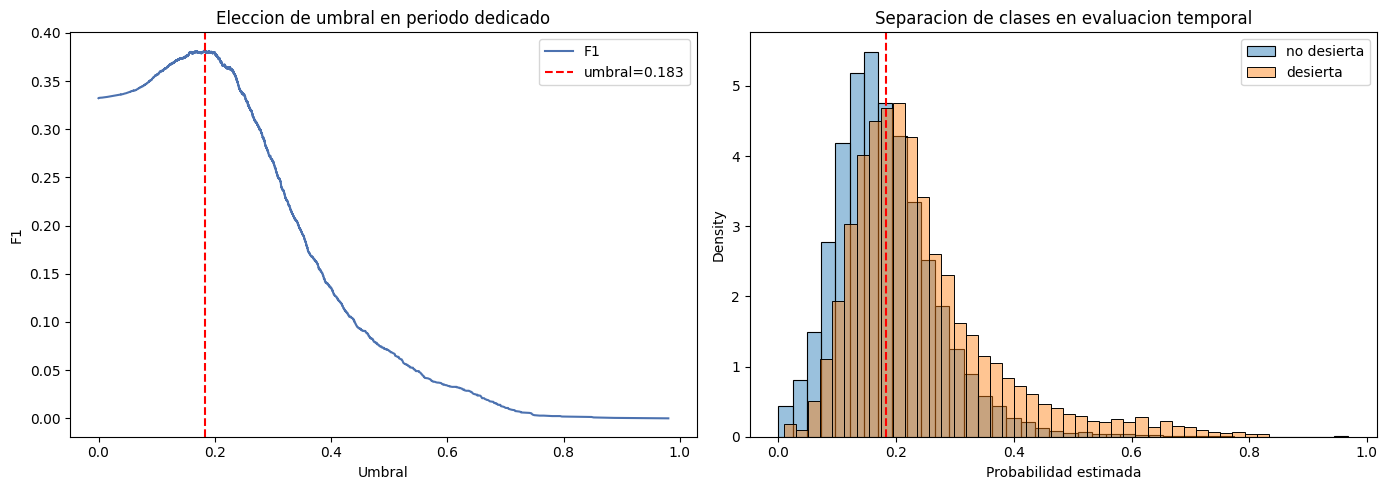

In [58]:
pred_test_temporal = (proba_test_temporal >= mejor_threshold).astype(int)

print(classification_report(
    y_test_temporal,
    pred_test_temporal,
    target_names=["no desierta", "desierta"],
    zero_division=0
))

precision, recall, thresholds = precision_recall_curve(y_val_umbral, proba_umbral)
f1_curve = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(thresholds, f1_curve, label="F1")
ax[0].axvline(mejor_threshold, color="red", linestyle="--", label=f"umbral={mejor_threshold:.3f}")
ax[0].set_xlabel("Umbral")
ax[0].set_ylabel("F1")
ax[0].set_title("Eleccion de umbral en periodo dedicado")
ax[0].legend()

sns.histplot(proba_test_temporal[y_test_temporal == 0], bins=40, stat="density", color="tab:blue", alpha=0.45, label="no desierta", ax=ax[1])
sns.histplot(proba_test_temporal[y_test_temporal == 1], bins=40, stat="density", color="tab:orange", alpha=0.45, label="desierta", ax=ax[1])
ax[1].axvline(mejor_threshold, color="red", linestyle="--")
ax[1].set_xlabel("Probabilidad estimada")
ax[1].set_title("Separacion de clases en evaluacion temporal")
ax[1].legend()
plt.tight_layout()

# Resultados y discusion

La comparacion anterior separa tres preguntas distintas. Primero, la regresion logistica estructural funciona como referencia directa para medir cuanto aportan el texto y los conteos historicos sin cambiar el tipo de clasificador. Segundo, la version con texto permite estimar el aporte de TF-IDF sobre las variables estructurales. Tercero, la version con conteos mide si el volumen historico de publicaciones agrega senal despues de controlar por texto y estructura.

No se usan tasas historicas de desiertas, sumas de `y_desierta`, prevalencias globales ni suavizados con etiquetas. Esta decision puede reducir F1, pero cumple la restriccion principal: no hay fecha de disponibilidad del desenlace para construir historial supervisado.

El F1 se maximiza mediante un umbral elegido explicitamente en C, pero ese objetivo no equivale necesariamente a minimizar costos operacionales. Sin costos cuantificados, no se afirma que un tipo de error sea mas caro; solo se reportan precision, recall, AP, ROC AUC, Brier Score y matriz de confusion para que la decision operacional pueda discutirse aparte.

In [59]:
def resumen_estabilidad(nombre, modelo, X, y, threshold):
    proba = modelo.predict_proba(X)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "particion": nombre,
        "n": len(y),
        "tasa_observada": y.mean(),
        "tasa_predicha": pred.mean(),
        "f1": f1_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "ap": average_precision_score(y, proba),
        "roc_auc": roc_auc_score(y, proba),
        "brier": brier_score_loss(y, proba)
    }

resumen_predicciones = pd.DataFrame([
    resumen_estabilidad("train_hparam", modelo_para_umbral, X_train_hparam, y_train_hparam, mejor_threshold),
    resumen_estabilidad("val_umbral", modelo_para_umbral, X_val_umbral, y_val_umbral, mejor_threshold),
    resumen_estabilidad("train_umbral", modelo_evaluacion, X_train_umbral, y_train_umbral, mejor_threshold),
    resumen_estabilidad("test_temporal", modelo_evaluacion, X_test_temporal, y_test_temporal, mejor_threshold)
])

resumen_predicciones

,particion,n,tasa_observada,tasa_predicha,f1,precision,recall,ap,roc_auc,brier
0,train_hparam,116666,0.200204,0.510131,0.441621,0.307469,0.783448,0.436260,0.743718,0.141387
1,val_umbral,21308,0.199221,0.463441,0.381445,0.272709,0.634393,0.331766,0.654811,0.150695
2,train_umbral,137974,0.200052,0.511299,0.436198,0.303433,0.775524,0.429242,0.738312,0.141861
3,test_temporal,14579,0.202003,0.483572,0.379190,0.268794,0.643463,0.344784,0.647093,0.151927


## Entrenamiento final y archivo de submission

Una vez elegido el modelo, sus hiperparametros y el umbral sin usar el bloque final de evaluacion, se reentrena con todo 2024. Para las licitaciones de 2025, los conteos historicos se calculan usando solamente publicaciones anteriores registradas en 2024; no se usa ninguna etiqueta de 2025 ni la columna de ejemplo de `sample_submission.csv`. Tambien se revisa la proporcion predicha de desiertas frente a la prevalencia observada en 2024; una diferencia grande no prueba por si sola descalibracion, porque el umbral F1 puede inducir tasas predichas altas.

In [60]:
datos_2024 = datos.copy()
test_features = construir_features(test_df, referencia=datos_2024)
X_2024 = construir_features(datos_2024)
y_2024 = datos_2024[TARGET].astype(int)

modelo_final = clone(mejor_modelo_config)
modelo_final.fit(X_2024, y_2024)

proba_test = modelo_final.predict_proba(test_features)[:, 1]
pred_test = (proba_test >= mejor_threshold).astype(int)

submission = pd.DataFrame({
    "id": test_df["id"],
    "y_desierta": pred_test
})

submission.to_csv("submission_pregunta2.csv", index=False)

comparacion_submission = pd.Series({
    "proporcion_observada_2024": y_2024.mean(),
    "proporcion_predicha_2025": submission["y_desierta"].mean(),
    "diferencia_predicha_vs_2024": submission["y_desierta"].mean() - y_2024.mean()
})
comparacion_submission

proporcion_observada_2024      0.200239
proporcion_predicha_2025       0.539283
diferencia_predicha_vs_2024    0.339044
dtype: float64

In [61]:
submission.head()

,id,y_desierta
0,47254358932,0
1,295671198916,0
2,214756376398,0
3,404842360472,1
4,899379189128,1


El archivo `submission_pregunta2.csv` queda listo para subir a Kaggle con las columnas exigidas: `id` y `y_desierta`. El umbral usado proviene de un periodo temporal dedicado a seleccion de umbral y no del leaderboard publico. Limitaciones no resueltas con los CSV disponibles: no hay diccionario oficial adjunto para certificar que texto, plazos, categorias y otros campos son exactamente la version visible al publicar; tampoco hay fecha de disponibilidad del desenlace, por lo que la validacion se reporta como retrospectiva por fecha de publicacion y se excluyen historiales supervisados.